In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_PATH = "/content/drive/MyDrive/AMEX_Credit_Risk_Capstone_Project"

DATA_PATH = os.path.join(PROJECT_PATH, "data", "processed")
MODELS_PATH = os.path.join(PROJECT_PATH, "models")
FIGURES_PATH = os.path.join(PROJECT_PATH, "results", "figures")
TABLES_PATH = os.path.join(PROJECT_PATH, "results", "tables")

print("✅ Project path:", PROJECT_PATH)
print("✅ Data path:", DATA_PATH)
print("✅ Models path:", MODELS_PATH)

Mounted at /content/drive
✅ Project path: /content/drive/MyDrive/AMEX_Credit_Risk_Capstone_Project
✅ Data path: /content/drive/MyDrive/AMEX_Credit_Risk_Capstone_Project/data/processed
✅ Models path: /content/drive/MyDrive/AMEX_Credit_Risk_Capstone_Project/models


In [2]:
import pandas as pd
import joblib

model_data = pd.read_csv(
    os.path.join(DATA_PATH, "modeling_data_30_features_70k.csv")
)

xgb_model = joblib.load(
    os.path.join(MODELS_PATH, "xgboost_model.pkl")
)

logistic_model = joblib.load(
    os.path.join(MODELS_PATH, "logistic_regression.pkl")
)

imputer = joblib.load(
    os.path.join(MODELS_PATH, "median_imputer.pkl")
)

scaler = joblib.load(
    os.path.join(MODELS_PATH, "standard_scaler.pkl")
)

In [3]:
print("Dataset shape:", model_data.shape)

print("\nXGBoost model:")
print(xgb_model)

print("\nLogistic Regression model:")
print(logistic_model)

print("\nImputer:", imputer)
print("Scaler:", scaler)

print("\nTarget distribution:")
print(model_data["target"].value_counts())

print("\nNumber of unique customers:",
      model_data["customer_ID"].nunique())

Dataset shape: (70000, 32)

XGBoost model:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

Logistic Regression model:
LogisticRegression(max_iter=1000, random_state=42)

Imputer: SimpleImputer(strategy='median')
Scaler: StandardScaler()

Target distribution:
target
0    5187

In [4]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = model_data.drop(columns=["customer_ID", "target"])
y = model_data["target"]

# Recreate the original 80/20 split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Apply the previously saved imputer
X_val_imputed = imputer.transform(X_val)

print("Training dataset:", X_train.shape)
print("Validation dataset:", X_val.shape)
print("Imputed validation dataset:", X_val_imputed.shape)

print("\nValidation target distribution:")
print(y_val.value_counts())

Training dataset: (56000, 30)
Validation dataset: (14000, 30)
Imputed validation dataset: (14000, 30)

Validation target distribution:
target
0    10375
1     3625
Name: count, dtype: int64


In [7]:
import os
import pandas as pd
RAW_PATH = os.path.join(PROJECT_PATH, "data", "raw")
PROCESSED_PATH = os.path.join(
    PROJECT_PATH, "data", "processed"
)

files = [
    "train_customer_ids.csv",
    "validation_customer_ids.csv",
    "test_customer_ids.csv"
]

for file in files:
    file_path = os.path.join(PROCESSED_PATH, file)

    print(f"\nChecking: {file}")
    print("Exists:", os.path.exists(file_path))

    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        print("Shape:", df.shape)
        print("Unique customers:", df.iloc[:, 0].nunique())


Checking: train_customer_ids.csv
Exists: True
Shape: (70000, 2)
Unique customers: 70000

Checking: validation_customer_ids.csv
Exists: True
Shape: (15000, 2)
Unique customers: 15000

Checking: test_customer_ids.csv
Exists: True
Shape: (15000, 2)
Unique customers: 15000


In [8]:
print("RAW DATA FILES:")
for f in os.listdir(RAW_PATH):
    print(f)

print("\nPROCESSED DATA FILES:")
for f in os.listdir(PROCESSED_PATH):
    print(f)

RAW DATA FILES:
sample_submission.csv
test_data.csv
train_data.csv
train_labels.csv
.complete

PROCESSED DATA FILES:
sample_100k_customers.csv
train_data_100k.csv
customer_features_100k.csv
train_data_100k_no_90pct_missing_v2.csv
train_customer_ids.csv
validation_customer_ids.csv
test_customer_ids.csv
train_monthly_70k_v2.csv
sample_100k_customers.gsheet
test_monthly_15k_v2.csv
validation_monthly_15k_v2.csv
train_customer_screening_70k.csv
modeling_data_30_features_70k.csv
modeling_data_30_features_70k.gsheet


In [9]:
import pandas as pd
import os

validation_path = os.path.join(
    DATA_PATH, "validation_monthly_15k_v2.csv"
)

test_path = os.path.join(
    DATA_PATH, "test_monthly_15k_v2.csv"
)

validation_monthly = pd.read_csv(validation_path)
test_monthly = pd.read_csv(test_path)

print("VALIDATION DATA")
print("Shape:", validation_monthly.shape)
print("Unique customers:", validation_monthly["customer_ID"].nunique())

print("\nTEST DATA")
print("Shape:", test_monthly.shape)
print("Unique customers:", test_monthly["customer_ID"].nunique())

VALIDATION DATA
Shape: (119424, 172)
Unique customers: 9906

TEST DATA
Shape: (90283, 172)
Unique customers: 7485


In [11]:
# Load original customer ID files
train_ids = pd.read_csv(
    os.path.join(DATA_PATH, "train_customer_ids.csv")
)

validation_ids = pd.read_csv(
    os.path.join(DATA_PATH, "validation_customer_ids.csv")
)

test_ids = pd.read_csv(
    os.path.join(DATA_PATH, "test_customer_ids.csv")
)

# Extract customer IDs
train_set = set(train_ids["customer_ID"])
validation_set = set(validation_ids["customer_ID"])
test_set = set(test_ids["customer_ID"])

# 1. Customer counts
print("=" * 50)
print("1. CUSTOMER SPLIT SUMMARY")
print("=" * 50)

print("Training customers:", len(train_set))
print("Validation customers:", len(validation_set))
print("Test customers:", len(test_set))

# 2. Duplicate check
print("\n" + "=" * 50)
print("2. DUPLICATE CUSTOMER CHECK")
print("=" * 50)

print("Training duplicates:", train_ids["customer_ID"].duplicated().sum())
print("Validation duplicates:", validation_ids["customer_ID"].duplicated().sum())
print("Test duplicates:", test_ids["customer_ID"].duplicated().sum())

# 3. Overlap check
print("\n" + "=" * 50)
print("3. CUSTOMER OVERLAP CHECK")
print("=" * 50)

print("Train-Validation overlap:", len(train_set & validation_set))
print("Train-Test overlap:", len(train_set & test_set))
print("Validation-Test overlap:", len(validation_set & test_set))

# 4. Total unique customers
all_customers = train_set | validation_set | test_set

print("\n" + "=" * 50)
print("4. TOTAL CUSTOMER VERIFICATION")
print("=" * 50)

print("Total unique customers:", len(all_customers))

# 5. Final verification
print("\n" + "=" * 50)
print("5. FINAL VALIDATION")
print("=" * 50)

checks = {
    "Training customers = 70,000": len(train_set) == 70000,
    "Validation customers = 15,000": len(validation_set) == 15000,
    "Test customers = 15,000": len(test_set) == 15000,
    "No training duplicates": train_ids["customer_ID"].is_unique,
    "No validation duplicates": validation_ids["customer_ID"].is_unique,
    "No test duplicates": test_ids["customer_ID"].is_unique,
    "No overlap between datasets": (
        len(train_set & validation_set) == 0
        and len(train_set & test_set) == 0
        and len(validation_set & test_set) == 0
    ),
    "Total unique customers = 100,000": len(all_customers) == 100000
}

for description, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {description}")

print("\nOverall result:",
      "ALL CHECKS PASSED" if all(checks.values()) else "CHECKS FAILED")

1. CUSTOMER SPLIT SUMMARY
Training customers: 70000
Validation customers: 15000
Test customers: 15000

2. DUPLICATE CUSTOMER CHECK
Training duplicates: 0
Validation duplicates: 0
Test duplicates: 0

3. CUSTOMER OVERLAP CHECK
Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0

4. TOTAL CUSTOMER VERIFICATION
Total unique customers: 100000

5. FINAL VALIDATION
PASS: Training customers = 70,000
PASS: Validation customers = 15,000
PASS: Test customers = 15,000
PASS: No training duplicates
PASS: No validation duplicates
PASS: No test duplicates
PASS: No overlap between datasets
PASS: Total unique customers = 100,000

Overall result: ALL CHECKS PASSED


In [12]:

# Load the correct cleaned master dataset
cleaned_path = os.path.join(
    DATA_PATH,
    "train_data_100k_no_90pct_missing_v2.csv"
)

cleaned_data = pd.read_csv(cleaned_path)

print("=" * 50)
print("1. MASTER DATASET SUMMARY")
print("=" * 50)

print("Dataset shape:", cleaned_data.shape)
print("Unique customers:", cleaned_data["customer_ID"].nunique())
print("Total monthly records:", len(cleaned_data))

# Extract customer IDs from master dataset
master_ids = set(cleaned_data["customer_ID"].unique())

print("\n" + "=" * 50)
print("2. CUSTOMER ID COVERAGE")
print("=" * 50)

print("Training IDs missing from master:", len(train_set - master_ids))
print("Validation IDs missing from master:", len(validation_set - master_ids))
print("Test IDs missing from master:", len(test_set - master_ids))

print("\n" + "=" * 50)
print("3. FINAL VERIFICATION")
print("=" * 50)

checks = {
    "Master contains 100,000 customers": len(master_ids) == 100000,
    "All training IDs exist in master": train_set.issubset(master_ids),
    "All validation IDs exist in master": validation_set.issubset(master_ids),
    "All test IDs exist in master": test_set.issubset(master_ids)
}

for description, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {description}")

print(
    "\nOverall result:",
    "ALL CHECKS PASSED" if all(checks.values()) else "CHECKS FAILED"
)

1. MASTER DATASET SUMMARY
Dataset shape: (1205473, 172)
Unique customers: 100000
Total monthly records: 1205473

2. CUSTOMER ID COVERAGE
Training IDs missing from master: 0
Validation IDs missing from master: 0
Test IDs missing from master: 0

3. FINAL VERIFICATION
PASS: Master contains 100,000 customers
PASS: All training IDs exist in master
PASS: All validation IDs exist in master
PASS: All test IDs exist in master

Overall result: ALL CHECKS PASSED


In [13]:
import os
import pandas as pd

# Create correct monthly datasets using customer IDs
train_monthly = cleaned_data[
    cleaned_data["customer_ID"].isin(train_set)
].copy()

validation_monthly = cleaned_data[
    cleaned_data["customer_ID"].isin(validation_set)
].copy()

test_monthly = cleaned_data[
    cleaned_data["customer_ID"].isin(test_set)
].copy()

# Save with new filenames to preserve the old files
train_path = os.path.join(
    DATA_PATH, "train_monthly_70k_corrected.csv"
)

validation_path = os.path.join(
    DATA_PATH, "validation_monthly_15k_corrected.csv"
)

test_path = os.path.join(
    DATA_PATH, "test_monthly_15k_corrected.csv"
)

train_monthly.to_csv(train_path, index=False)
validation_monthly.to_csv(validation_path, index=False)
test_monthly.to_csv(test_path, index=False)

print("MONTHLY DATASETS CREATED SUCCESSFULLY")
print("-" * 50)

print("Training shape:", train_monthly.shape)
print("Training unique customers:",
      train_monthly["customer_ID"].nunique())

print("\nValidation shape:", validation_monthly.shape)
print("Validation unique customers:",
      validation_monthly["customer_ID"].nunique())

print("\nTest shape:", test_monthly.shape)
print("Test unique customers:",
      test_monthly["customer_ID"].nunique())

print("\nSaved files:")
print(train_path)
print(validation_path)
print(test_path)

MONTHLY DATASETS CREATED SUCCESSFULLY
--------------------------------------------------
Training shape: (844173, 172)
Training unique customers: 70000

Validation shape: (180653, 172)
Validation unique customers: 15000

Test shape: (180647, 172)
Test unique customers: 15000

Saved files:
/content/drive/MyDrive/AMEX_Credit_Risk_Capstone_Project/data/processed/train_monthly_70k_corrected.csv
/content/drive/MyDrive/AMEX_Credit_Risk_Capstone_Project/data/processed/validation_monthly_15k_corrected.csv
/content/drive/MyDrive/AMEX_Credit_Risk_Capstone_Project/data/processed/test_monthly_15k_corrected.csv


In [14]:
# Verify customer coverage in reconstructed monthly datasets
monthly_splits = {
    "Training": (train_monthly, train_set, 70000),
    "Validation": (validation_monthly, validation_set, 15000),
    "Test": (test_monthly, test_set, 15000)
}

print("=" * 60)
print("RECONSTRUCTED MONTHLY DATASET VERIFICATION")
print("=" * 60)

all_passed = True

for name, (df, expected_ids, expected_count) in monthly_splits.items():

    actual_ids = set(df["customer_ID"].unique())

    missing_ids = expected_ids - actual_ids
    unexpected_ids = actual_ids - expected_ids

    passed = (
        len(actual_ids) == expected_count
        and len(missing_ids) == 0
        and len(unexpected_ids) == 0
    )

    all_passed = all_passed and passed

    print(f"\n{name.upper()}")
    print("Monthly records:", len(df))
    print("Unique customers:", len(actual_ids))
    print("Expected customers:", expected_count)
    print("Missing customers:", len(missing_ids))
    print("Unexpected customers:", len(unexpected_ids))
    print("Status:", "PASS" if passed else "FAIL")

print("\n" + "=" * 60)
print("OVERALL RESULT:",
      "ALL CHECKS PASSED" if all_passed else "CHECKS FAILED")

RECONSTRUCTED MONTHLY DATASET VERIFICATION

TRAINING
Monthly records: 844173
Unique customers: 70000
Expected customers: 70000
Missing customers: 0
Unexpected customers: 0
Status: PASS

VALIDATION
Monthly records: 180653
Unique customers: 15000
Expected customers: 15000
Missing customers: 0
Unexpected customers: 0
Status: PASS

TEST
Monthly records: 180647
Unique customers: 15000
Expected customers: 15000
Missing customers: 0
Unexpected customers: 0
Status: PASS

OVERALL RESULT: ALL CHECKS PASSED


In [15]:
# Load existing modelling dataset
modeling_data = pd.read_csv(
    os.path.join(DATA_PATH, "modeling_data_30_features_70k.csv")
)

# Extract customer IDs
modeling_ids = set(modeling_data["customer_ID"].unique())

print("=" * 50)
print("EXISTING MODELLING DATASET VERIFICATION")
print("=" * 50)

print("Existing modelling customers:", len(modeling_ids))
print("Correct training customers:", len(train_set))

print("Missing training IDs:", len(train_set - modeling_ids))
print("Unexpected IDs:", len(modeling_ids - train_set))

print("\nRESULT:",
      "MATCH" if modeling_ids == train_set else "DO NOT MATCH")

EXISTING MODELLING DATASET VERIFICATION
Existing modelling customers: 70000
Correct training customers: 70000
Missing training IDs: 0
Unexpected IDs: 0

RESULT: MATCH


In [16]:
# 1. Inspect modelling dataset columns
print("MODELLING DATASET COLUMNS")
print(modeling_data.columns.tolist())

print("\nNumber of selected features:",
      len([c for c in modeling_data.columns
           if c not in ["customer_ID", "target"]]))

# 2. Inspect validation ID file
print("\nVALIDATION ID FILE")
print(validation_ids.head())
print("Columns:", validation_ids.columns.tolist())

# 3. Check saved model files
print("\nSAVED MODEL FILES")

for filename in [
    "logistic_regression.pkl",
    "xgboost_model.pkl",
    "median_imputer.pkl",
    "standard_scaler.pkl"
]:
    path = os.path.join(MODELS_PATH, filename)
    print(filename, "EXISTS" if os.path.exists(path) else "NOT FOUND")

MODELLING DATASET COLUMNS
['customer_ID', 'P_2_last', 'D_48_last', 'B_2_last', 'D_61_last', 'B_9_last', 'B_18_last', 'D_55_last', 'D_61_mean', 'B_2_mean', 'D_44_last', 'B_9_mean', 'R_1_mean', 'B_3_last', 'D_75_last', 'B_7_last', 'R_1_last', 'B_4_last', 'B_20_last', 'B_19_last', 'B_38_last', 'B_1_last', 'B_23_mean', 'R_2_last', 'B_22_mean', 'R_10_mean', 'B_17_mean', 'B_38_mean', 'B_22_last', 'B_1_mean', 'B_30_last', 'target']

Number of selected features: 30

VALIDATION ID FILE
                                         customer_ID  target
0  4b86dddbb8240bc27bc229da12a1a5f2a7f366e76fe84a...       1
1  f2cf0f3536e84989a217811bc19e41dda3167c80ba8e3a...       0
2  4b12c1042232861898992b92df06e23001faad00c91dd0...       0
3  0ead6483519b3c21579284d26d1535454f91584a777abe...       0
4  d166083ad3f264a84bcfb8420ff64a4a6ae72bb246f6e7...       1
Columns: ['customer_ID', 'target']

SAVED MODEL FILES
logistic_regression.pkl EXISTS
xgboost_model.pkl EXISTS
median_imputer.pkl EXISTS
standard_scaler.

In [18]:

# 1. Get the selected customer-level features
selected_features = [
    col for col in modeling_data.columns
    if col not in ["customer_ID", "target"]
]

# 2. Extract original monthly feature names
monthly_features = list(dict.fromkeys(
    col.rsplit("_", 1)[0]
    for col in selected_features
))

print("Selected customer-level features:", len(selected_features))
print("Original monthly features:", len(monthly_features))

# 3. Verify that all original features exist
missing_columns = [
    col for col in monthly_features
    if col not in validation_monthly.columns
]

print("Missing monthly columns:", missing_columns)

# 4. Sort records chronologically
validation_monthly = validation_monthly.sort_values(
    ["customer_ID", "S_2"]
)

# 5. Calculate customer-level mean
validation_mean = (
    validation_monthly
    .groupby("customer_ID")[monthly_features]
    .mean()
)

# 6. Calculate last observed values
validation_last = (
    validation_monthly
    .groupby("customer_ID")[monthly_features]
    .last()
)

# 7. Add suffixes
validation_mean.columns = [
    col + "_mean" for col in validation_mean.columns
]

validation_last.columns = [
    col + "_last" for col in validation_last.columns
]

# 8. Combine aggregated features
validation_features = pd.concat(
    [validation_mean, validation_last],
    axis=1
).reset_index()

# 9. Keep exactly the original 30 selected features
validation_features = validation_features[
    ["customer_ID"] + selected_features
]

# 10. Attach actual target labels
validation_features = validation_features.merge(
    validation_ids[["customer_ID", "target"]],
    on="customer_ID",
    how="left",
    validate="one_to_one"
)

# 11. Arrange columns in training order
validation_features = validation_features[
    modeling_data.columns
]

# 12. Save
validation_features.to_csv(
    os.path.join(DATA_PATH, "validation_modeling_data_15k.csv"),
    index=False
)

# 13. Display results
print("\nVALIDATION DATASET SUMMARY")
print("Shape:", validation_features.shape)
print("Unique customers:",
      validation_features["customer_ID"].nunique())

print("\nTarget distribution:")
print(validation_features["target"].value_counts())

print("\nMissing feature values:",
      validation_features[selected_features].isnull().sum().sum())

print("\nSaved successfully!")

Selected customer-level features: 30
Original monthly features: 23
Missing monthly columns: []

VALIDATION DATASET SUMMARY
Shape: (15000, 32)
Unique customers: 15000

Target distribution:
target
0    11116
1     3884
Name: count, dtype: int64

Missing feature values: 10057

Saved successfully!


In [19]:
# Compare training and validation feature structures

print("=" * 55)
print("TRAINING VS VALIDATION FEATURE COMPARISON")
print("=" * 55)

train_features = modeling_data[selected_features]

validation_feature_values = validation_features[selected_features]

print("\nTraining shape:", train_features.shape)
print("Validation shape:", validation_feature_values.shape)

print("\nMissing values:")
print("Training:", train_features.isnull().sum().sum())
print("Validation:", validation_feature_values.isnull().sum().sum())

print("\nData type comparison:")
print("Training numeric columns:",
      train_features.select_dtypes(include="number").shape[1])

print("Validation numeric columns:",
      validation_feature_values.select_dtypes(include="number").shape[1])

print("\nFeature order matches:",
      list(train_features.columns) == list(validation_feature_values.columns))

print("\nValidation feature summary:")
display(validation_feature_values.describe().T)

TRAINING VS VALIDATION FEATURE COMPARISON

Training shape: (70000, 30)
Validation shape: (15000, 30)

Missing values:
Training: 60375
Validation: 10057

Data type comparison:
Training numeric columns: 30
Validation numeric columns: 30

Feature order matches: True

Validation feature summary:


,count,mean,std,min,25%,50%,75%,max
P_2_last,14916.0,0.633866,0.267903,-3.437710e-01,0.447222,0.675867,0.861112,1.009994
D_48_last,14058.0,0.392813,0.345580,-9.603428e-03,0.070458,0.281927,0.721386,3.194147
B_2_last,14998.0,0.591239,0.411971,2.941834e-05,0.071503,0.813389,1.001901,1.009999
D_61_last,14301.0,0.436892,0.352488,-9.131704e-03,0.084184,0.374099,0.805182,3.036448
B_9_last,15000.0,0.206091,0.291958,2.817300e-07,0.005676,0.027360,0.431433,5.247134
B_18_last,15000.0,0.570775,0.372970,1.281724e-05,0.200192,0.590917,1.002962,1.009999
D_55_last,14917.0,0.315268,0.305103,2.110858e-06,0.054766,0.192393,0.549409,2.767759
D_61_mean,14301.0,0.421323,0.315235,-7.742532e-03,0.113063,0.379194,0.722459,3.035632
B_2_mean,14998.0,0.620014,0.351579,7.295245e-04,0.258976,0.814051,0.910038,1.009981
D_44_last,14439.0,0.140419,0.246440,1.676704e-06,0.004018,0.008027,0.134179,2.881733


In [20]:
# Load existing preprocessing objects
imputer = joblib.load(
    os.path.join(MODELS_PATH, "median_imputer.pkl")
)

scaler = joblib.load(
    os.path.join(MODELS_PATH, "standard_scaler.pkl")
)

print("=" * 55)
print("PREPROCESSING OBJECT VERIFICATION")
print("=" * 55)

print("Number of selected features:", len(selected_features))

print("\nImputer:")
print("Number of features fitted:", imputer.n_features_in_)

print("\nScaler:")
print("Number of features fitted:", scaler.n_features_in_)

# Check fitted feature names, if available
if hasattr(imputer, "feature_names_in_"):
    print("\nImputer feature order matches:",
          list(imputer.feature_names_in_) == selected_features)

if hasattr(scaler, "feature_names_in_"):
    print("Scaler feature order matches:",
          list(scaler.feature_names_in_) == selected_features)

print("\nImputer and scaler loaded successfully.")

PREPROCESSING OBJECT VERIFICATION
Number of selected features: 30

Imputer:
Number of features fitted: 30

Scaler:
Number of features fitted: 30

Imputer feature order matches: True

Imputer and scaler loaded successfully.


In [22]:
import numpy as np
import pandas as pd

# 1. Separate validation features and target
X_validation = validation_features[selected_features].copy()
y_validation = validation_features["target"].copy()

# 2. Apply existing training-fitted median imputer
X_validation_imputed = imputer.transform(X_validation)

# Convert back to DataFrame
X_validation_imputed = pd.DataFrame(
    X_validation_imputed,
    columns=selected_features,
    index=X_validation.index
)

# 3. Apply existing scaler for Logistic Regression only
X_validation_scaled = scaler.transform(X_validation_imputed)

X_validation_scaled = pd.DataFrame(
    X_validation_scaled,
    columns=selected_features,
    index=X_validation.index
)

# 4. Check results
print("=" * 55)
print("VALIDATION PREPROCESSING SUMMARY")
print("=" * 55)

print("Original validation shape:", X_validation.shape)
print("Imputed validation shape:", X_validation_imputed.shape)
print("Scaled validation shape:", X_validation_scaled.shape)

print("\nMissing values after imputation:",
      X_validation_imputed.isnull().sum().sum())

print("\nInfinite values after imputation:",
      np.isinf(X_validation_imputed.to_numpy()).sum())

print("\nInfinite values after scaling:",
      np.isinf(X_validation_scaled.to_numpy()).sum())

print("\nTarget shape:", y_validation.shape)

print("\nPreprocessing completed!")

VALIDATION PREPROCESSING SUMMARY
Original validation shape: (15000, 30)
Imputed validation shape: (15000, 30)
Scaled validation shape: (15000, 30)

Missing values after imputation: 0

Infinite values after imputation: 0

Infinite values after scaling: 0

Target shape: (15000,)

Preprocessing completed!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [23]:
X_validation_scaled = scaler.transform(
    X_validation_imputed.to_numpy()
)

X_validation_scaled = pd.DataFrame(
    X_validation_scaled,
    columns=selected_features,
    index=X_validation.index
)

In [24]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib
import os

# Load existing models
lr_model = joblib.load(
    os.path.join(MODELS_PATH, "logistic_regression.pkl")
)

xgb_model = joblib.load(
    os.path.join(MODELS_PATH, "xgboost_model.pkl")
)

# Generate probabilities
lr_prob = lr_model.predict_proba(X_validation_scaled)[:, 1]

xgb_prob = xgb_model.predict_proba(X_validation_imputed)[:, 1]

# Generate class predictions using threshold 0.5
lr_pred = (lr_prob >= 0.5).astype(int)

xgb_pred = (xgb_prob >= 0.5).astype(int)

# Evaluation function
def evaluate_model(name, y_true, y_pred, y_prob):

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("ROC-AUC:",
          round(roc_auc_score(y_true, y_prob), 4))

    print("PR-AUC:",
          round(average_precision_score(y_true, y_prob), 4))

    print("Accuracy:",
          round(accuracy_score(y_true, y_pred), 4))

    print("Precision:",
          round(precision_score(y_true, y_pred), 4))

    print("Recall:",
          round(recall_score(y_true, y_pred), 4))

    print("F1-score:",
          round(f1_score(y_true, y_pred), 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# Evaluate both models
evaluate_model(
    "LOGISTIC REGRESSION - RESERVED VALIDATION",
    y_validation,
    lr_pred,
    lr_prob
)

evaluate_model(
    "XGBOOST - RESERVED VALIDATION",
    y_validation,
    xgb_pred,
    xgb_prob
)


LOGISTIC REGRESSION - RESERVED VALIDATION
ROC-AUC: 0.9428
PR-AUC: 0.8512
Accuracy: 0.881
Precision: 0.7819
Recall: 0.7495
F1-score: 0.7653

Confusion Matrix:
[[10304   812]
 [  973  2911]]

XGBOOST - RESERVED VALIDATION
ROC-AUC: 0.9483
PR-AUC: 0.8658
Accuracy: 0.8872
Precision: 0.7812
Recall: 0.784
F1-score: 0.7826

Confusion Matrix:
[[10263   853]
 [  839  3045]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


#SHAP Implementation

In [25]:
# Install SHAP if required
!pip install shap -q

In [26]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import os

# Check SHAP version
print("SHAP version:", shap.__version__)

# Load the existing trained XGBoost model
xgb_model = joblib.load(
    os.path.join(MODELS_PATH, "xgboost_model.pkl")
)

# Use the already-imputed reserved validation dataset
# Select a reproducible sample of 2,000 customers
X_shap = X_validation_imputed.sample(
    n=2000,
    random_state=42
).copy()

print("\nSHAP DATASET SUMMARY")
print("Shape:", X_shap.shape)
print("Number of features:", X_shap.shape[1])
print("Number of customers:", X_shap.shape[0])
print("Missing values:", X_shap.isnull().sum().sum())

print("\nXGBoost model loaded successfully!")

SHAP version: 0.54.1

SHAP DATASET SUMMARY
Shape: (2000, 30)
Number of features: 30
Number of customers: 2000
Missing values: 0

XGBoost model loaded successfully!


In [27]:
# ============================================================
# STEP 2: CREATE SHAP TREE EXPLAINER
# ============================================================

# TreeExplainer is specifically designed for tree-based models.
# Since our improved model is XGBoost, this is an appropriate
# SHAP explainer for our project.

explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values for the 2,000 validation customers.
# Each SHAP value represents a feature's contribution to the
# model's prediction for a particular customer.

shap_values = explainer(X_shap)

# Display the dimensions of the calculated SHAP values.
print("SHAP EXPLAINER CREATED SUCCESSFULLY")

print("\nSHAP values shape:", shap_values.values.shape)

print("Number of customers:", shap_values.values.shape[0])

print("Number of features:", shap_values.values.shape[1])

print("\nExpected value (base value):",
      explainer.expected_value)

SHAP EXPLAINER CREATED SUCCESSFULLY

SHAP values shape: (2000, 30)
Number of customers: 2000
Number of features: 30

Expected value (base value): -1.0739633


In [28]:
# ============================================================
# STEP 3: CALCULATE GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

# Calculate the mean absolute SHAP value for each feature.
# This measures the average magnitude of each feature's
# contribution across the 2,000 validation customers.

shap_importance = np.abs(shap_values.values).mean(axis=0)

# Create a DataFrame to organise feature importance results.
feature_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": shap_importance
})

# Sort features from highest to lowest importance.
feature_importance = feature_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Add ranking to make the results easier to interpret.
feature_importance.insert(
    0,
    "Rank",
    range(1, len(feature_importance) + 1)
)

# Display the top 15 most influential features.
print("TOP 15 FEATURES BASED ON SHAP IMPORTANCE")

display(feature_importance.head(15))

# Save the complete 30-feature importance table.
feature_importance.to_csv(
    os.path.join(TABLES_PATH, "shap_global_feature_importance.csv"),
    index=False
)

print("\nFeature importance table saved successfully!")

TOP 15 FEATURES BASED ON SHAP IMPORTANCE


,Rank,Feature,Mean_Absolute_SHAP
0,1,P_2_last,1.533873
1,2,B_1_last,0.332824
2,3,D_48_last,0.235613
3,4,B_9_last,0.213809
4,5,B_4_last,0.192799
5,6,B_2_mean,0.175829
6,7,B_3_last,0.169999
7,8,B_7_last,0.164714
8,9,R_1_mean,0.160421
9,10,B_2_last,0.154776



Feature importance table saved successfully!


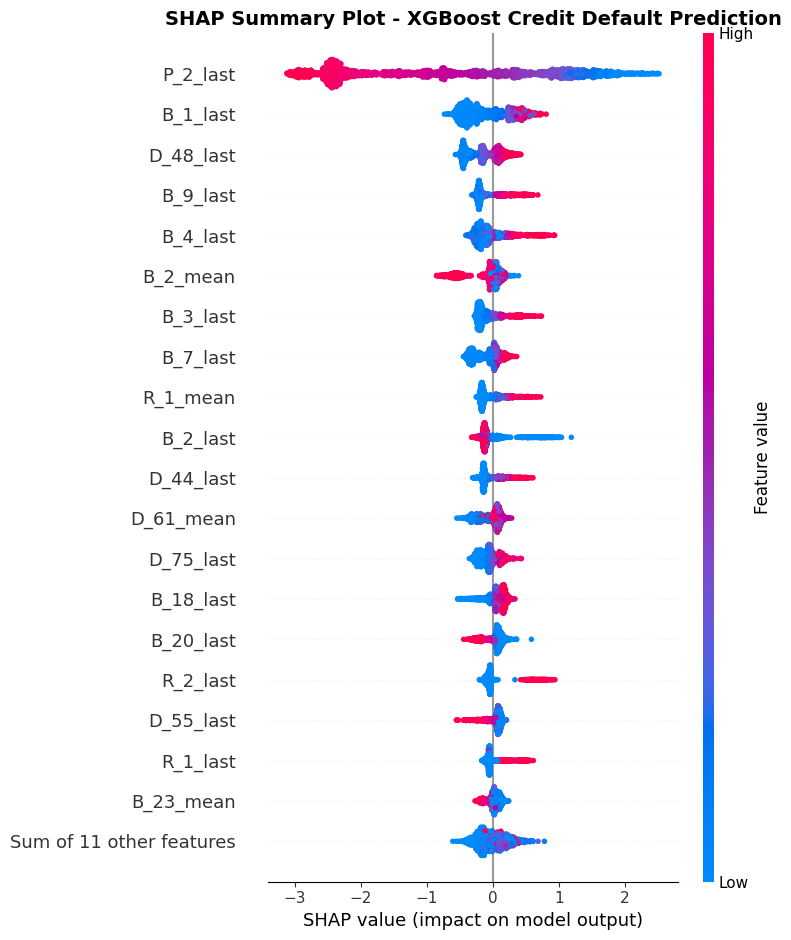

SHAP beeswarm plot saved successfully!


In [29]:
# ============================================================
# STEP 4: SHAP SUMMARY BEESWARM PLOT
# ============================================================

# Create a folder for SHAP visualisations if it doesn't exist.
SHAP_PATH = os.path.join(FIGURES_PATH, "shap")

os.makedirs(SHAP_PATH, exist_ok=True)

# Generate the SHAP beeswarm plot.
# Each dot represents one customer's SHAP contribution.
# Red indicates relatively high feature values.
# Blue indicates relatively low feature values.
# The horizontal position shows the SHAP contribution.

plt.figure(figsize=(12, 9))

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

# Add a descriptive title.
plt.title(
    "SHAP Summary Plot - XGBoost Credit Default Prediction",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# Save the visualisation at high resolution.
plt.savefig(
    os.path.join(SHAP_PATH, "shap_summary_beeswarm.png"),
    dpi=300,
    bbox_inches="tight"
)

# Display the plot in Google Colab.
plt.show()

print("SHAP beeswarm plot saved successfully!")

<Figure size 1000x600 with 0 Axes>

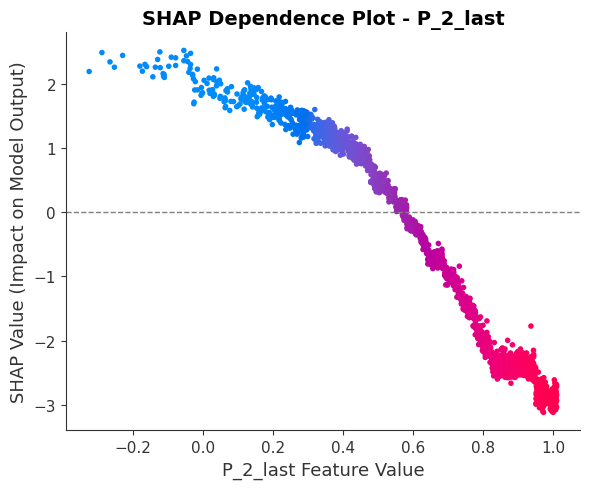

Coloured P_2_last dependence plot saved successfully!


In [31]:


# ============================================================
# STEP 5: SHAP DEPENDENCE PLOT WITH COLOUR CODING
# ============================================================

# Create the SHAP visualisation folder if it does not exist.
SHAP_PATH = os.path.join(FIGURES_PATH, "shap")
os.makedirs(SHAP_PATH, exist_ok=True)

# Create a figure for the dependence plot.
plt.figure(figsize=(10, 6))

# Generate the dependence plot.
# interaction_index="P_2_last" colours dots using P_2_last values.
# Red represents high values and blue represents low values.
shap.dependence_plot(
    "P_2_last",
    shap_values.values,
    X_shap,
    interaction_index="P_2_last",
    show=False
)

# Add the plot title and axis labels.
plt.title(
    "SHAP Dependence Plot - P_2_last",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("P_2_last Feature Value")
plt.ylabel("SHAP Value (Impact on Model Output)")

# Add a horizontal reference line at zero.
plt.axhline(y=0, color="grey", linestyle="--", linewidth=1)

# Adjust the layout.
plt.tight_layout()

# Save the plot as a high-resolution image.
plt.savefig(
    os.path.join(SHAP_PATH, "shap_dependence_P2_last_coloured.png"),
    dpi=300,
    bbox_inches="tight"
)

# Display the plot.
plt.show()

print("Coloured P_2_last dependence plot saved successfully!")


In [32]:

# ============================================================
# STEP 6.1: VERIFY CUSTOMER ID AND VALIDATION DATA ALIGNMENT
# ============================================================

# Load the customer-level validation dataset.
# This file contains customer IDs, selected features and target.
validation_modeling_data_15k = pd.read_csv(
    os.path.join(DATA_PATH, "validation_modeling_data_15k.csv")
)

# Check the number of customers in the validation dataset.
print("Validation dataset shape:", validation_modeling_data_15k.shape)

# Check the number of rows in the imputed feature dataset.
print("Imputed feature dataset shape:", X_validation_imputed.shape)

# Check whether both datasets contain the same number of customers.
print(
    "Number of customers matches:",
    len(validation_modeling_data_15k) == len(X_validation_imputed)
)

# Display the first five customer IDs.
print("\nFirst five validation customer IDs:")
print(validation_modeling_data_15k["customer_ID"].head())

# Check whether the selected feature columns match the model input.
print("\nNumber of model features:", X_validation_imputed.shape[1])

# Check whether the validation dataset contains the target column.
print("\nTarget column available:",
      "target" in validation_modeling_data_15k.columns)


Validation dataset shape: (15000, 32)
Imputed feature dataset shape: (15000, 30)
Number of customers matches: True

First five validation customer IDs:
0    000098081fde4fd64bc4d503a5d6f86a0aedc425c96f52...
1    0000f99513770170a1aba690daeeb8a96da4a39f11fc27...
2    0004b8596c4946866d1b27a8b40488ecf49c6eae9c7bf4...
3    001367d141f4934b83746b5f9c0335032b48f45c63d9b7...
4    0014e4c67ceef08a476bd84f4a64dd66360c9c4df7caca...
Name: customer_ID, dtype: object

Number of model features: 30

Target column available: True


In [33]:

# ============================================================
# STEP 6.2: VERIFY CUSTOMER ID AND FEATURE ROW ALIGNMENT
# ============================================================

# Extract customer IDs in the same order as the validation dataset.
validation_customer_ids = (
    validation_modeling_data_15k["customer_ID"]
    .reset_index(drop=True)
)

# Check whether the original validation feature DataFrame exists.
if "X_validation" not in globals():
    raise ValueError(
        "X_validation is not available. We need to identify "
        "the original validation features before proceeding."
    )

# Reset indexes to make row-by-row comparison possible.
original_validation_features = X_validation.reset_index(drop=True)

# Extract the 30 selected features from the customer-level dataset.
expected_validation_features = (
    validation_modeling_data_15k[selected_features]
    .reset_index(drop=True)
)

# Verify that feature columns are in the same order.
columns_match = (
    list(original_validation_features.columns)
    == list(expected_validation_features.columns)
)

# Verify that the original feature values match the dataset.
# Missing values are treated as equal during this comparison.
features_match = original_validation_features.equals(
    expected_validation_features
)

# Check that the number of customer IDs matches the feature rows.
row_count_match = (
    len(validation_customer_ids) == len(X_validation_imputed)
)

# Display the verification results.
print("Customer IDs:", len(validation_customer_ids))
print("Imputed feature rows:", len(X_validation_imputed))
print("Feature columns match:", columns_match)
print("Original feature values match:", features_match)
print("Customer and feature row counts match:", row_count_match)

# Confirm whether all alignment checks passed.
if columns_match and features_match and row_count_match:
    print("\nSUCCESS: Customer IDs and feature rows are aligned.")
else:
    print("\nWARNING: Alignment verification failed.")
    print("Do not generate individual explanations yet.")


Customer IDs: 15000
Imputed feature rows: 15000
Feature columns match: True
Original feature values match: False
Customer and feature row counts match: True

Do not generate individual explanations yet.


In [34]:

# ============================================================
# STEP 6.3: INVESTIGATE FEATURE VALUE MISMATCH
# ============================================================


# Convert both feature datasets to NumPy arrays.
# This allows us to compare their underlying values.
original_array = X_validation.reset_index(drop=True).to_numpy()

expected_array = (
    validation_modeling_data_15k[selected_features]
    .reset_index(drop=True)
    .to_numpy()
)

# Check whether the arrays have the same dimensions.
print("Original array shape:", original_array.shape)
print("Expected array shape:", expected_array.shape)

# Compare the two arrays while treating missing values as equal.
# A small tolerance allows for minor floating-point differences.
try:
    values_match = np.allclose(
        original_array.astype(float),
        expected_array.astype(float),
        rtol=1e-7,
        atol=1e-10,
        equal_nan=True
    )
except (ValueError, TypeError):
    values_match = False

print("\nValues match within numerical tolerance:", values_match)

# Count missing values in both datasets.
print("\nMissing values in X_validation:",
      X_validation.isna().sum().sum())

print("Missing values in expected validation features:",
      validation_modeling_data_15k[selected_features].isna().sum().sum())

# Calculate the number of cells with different values.
# Missing values in matching positions are treated as equal.
comparison = pd.DataFrame(
    np.isclose(
        original_array.astype(float),
        expected_array.astype(float),
        rtol=1e-7,
        atol=1e-10,
        equal_nan=True
    ),
    columns=selected_features
)

# Count how many cells differ.
different_cells = (~comparison).sum().sum()

print("\nNumber of different feature cells:", different_cells)

# Display the features with the highest number of mismatches.
mismatch_by_feature = (~comparison).sum().sort_values(
    ascending=False
)

print("\nMismatches by feature:")
print(mismatch_by_feature[mismatch_by_feature > 0].head(10))


Original array shape: (15000, 30)
Expected array shape: (15000, 30)

Values match within numerical tolerance: True

Missing values in X_validation: 10057
Missing values in expected validation features: 10057

Number of different feature cells: 0

Mismatches by feature:
Series([], dtype: int64)


In [35]:

# ============================================================
# STEP 6.4: SELECT ONE CUSTOMER FOR SHAP EXPLANATION
# ============================================================

# Select a customer using a fixed random seed.
# This makes the selection reproducible.
customer_index = 42

# Retrieve the customer's ID.
customer_id = validation_customer_ids.iloc[customer_index]

# Retrieve the customer's 30 imputed feature values.
# Keep the DataFrame structure required by XGBoost.
customer_features = X_validation_imputed.iloc[
    [customer_index]
].copy()

# Retrieve the customer's actual target value.
actual_target = validation_modeling_data_15k[
    "target"
].iloc[customer_index]

# Display the selected customer's information.
print("Selected Customer ID:", customer_id)
print("Customer Row Index:", customer_index)

# Display the actual outcome.
if actual_target == 1:
    print("Actual Outcome: Default")
else:
    print("Actual Outcome: Non-default")

# Display the feature dataset shape.
print("\nCustomer feature shape:", customer_features.shape)

# Display the customer's feature values.
display(customer_features.T)


Selected Customer ID: 00dae539b315802284dd4ea601580ff74d537a36e224deb7351974494f450cae
Customer Row Index: 42
Actual Outcome: Non-default

Customer feature shape: (1, 30)


,42
P_2_last,0.912723
D_48_last,0.084543
B_2_last,1.003552
D_61_last,0.083680
B_9_last,0.028578
B_18_last,1.001800
D_55_last,0.066873
D_61_mean,0.073420
B_2_mean,0.989658
D_44_last,0.002410


In [36]:

# ============================================================
# STEP 6.5: INDIVIDUAL CUSTOMER DEFAULT PREDICTION
# ============================================================

# Load the previously trained XGBoost model if it is not loaded.
if "xgb_model" not in globals():
    xgb_model = joblib.load(
        os.path.join(MODELS_PATH, "xgboost_model.pkl")
    )

# Predict the probability of each class.
# Class 0 = Non-default.
# Class 1 = Default.
# XGBoost uses the imputed, unscaled feature values.
customer_probabilities = xgb_model.predict_proba(
    customer_features
)[0]

# Extract the probability of default (class 1).
default_probability = customer_probabilities[1]

# Extract the probability of non-default (class 0).
non_default_probability = customer_probabilities[0]

# Predict the final class using the existing 0.5 threshold.
predicted_class = int(default_probability >= 0.5)

# Display the prediction results.
print("CUSTOMER-LEVEL PREDICTION")
print("=" * 45)

print("Customer ID:", customer_id)

print(
    f"Probability of Non-default: "
    f"{non_default_probability:.2%}"
)

print(
    f"Probability of Default: "
    f"{default_probability:.2%}"
)

print(
    "Predicted Class:",
    predicted_class,
    "(Default)" if predicted_class == 1 else "(Non-default)"
)

print(
    "Actual Class:",
    actual_target,
    "(Default)" if actual_target == 1 else "(Non-default)"
)

# Compare the predicted class with the actual outcome.
if predicted_class == actual_target:
    print("\nPrediction matches the actual outcome.")
else:
    print("\nPrediction differs from the actual outcome.")


CUSTOMER-LEVEL PREDICTION
Customer ID: 00dae539b315802284dd4ea601580ff74d537a36e224deb7351974494f450cae
Probability of Non-default: 99.84%
Probability of Default: 0.16%
Predicted Class: 0 (Non-default)
Actual Class: 0 (Non-default)

Prediction matches the actual outcome.


In [37]:

# ============================================================
# STEP 6.6: INDIVIDUAL CUSTOMER SHAP EXPLANATION
# ============================================================

# Create an explanation for this individual customer.
# We use the same TreeExplainer created for the XGBoost model.
customer_shap_values = explainer(customer_features)

# Extract the SHAP contributions for the 30 features.
# Each value represents one feature's contribution to the prediction.
customer_contributions = customer_shap_values.values[0]

# Create a DataFrame containing feature names and SHAP values.
customer_shap_df = pd.DataFrame({
    "Feature": customer_features.columns,
    "SHAP_Value": customer_contributions
})

# Sort features by the absolute size of their SHAP contribution.
# This identifies the features with the strongest influence.
customer_shap_df["Absolute_SHAP"] = (
    customer_shap_df["SHAP_Value"].abs()
)

customer_shap_df = customer_shap_df.sort_values(
    "Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Assign an interpretation based on the SHAP contribution direction.
# Positive SHAP values push towards default.
# Negative SHAP values push away from default.
customer_shap_df["Direction"] = np.where(
    customer_shap_df["SHAP_Value"] > 0,
    "Increases default output",
    np.where(
        customer_shap_df["SHAP_Value"] < 0,
        "Reduces default output",
        "No contribution"
    )
)

# Display the customer's five strongest feature contributions.
print("TOP 10 CUSTOMER-LEVEL SHAP CONTRIBUTIONS")
print("=" * 65)

display(
    customer_shap_df[
        ["Feature", "SHAP_Value", "Direction"]
    ].head(10)
)

# Separate features that increase and reduce the default output.
increasing_features = customer_shap_df[
    customer_shap_df["SHAP_Value"] > 0
]

reducing_features = customer_shap_df[
    customer_shap_df["SHAP_Value"] < 0
]

# Display the number of features in each direction.
print("\nNumber of features increasing default output:",
      len(increasing_features))

print("Number of features reducing default output:",
      len(reducing_features))

# Save all 30 feature contributions for later reporting.
customer_shap_df.to_csv(
    os.path.join(
        TABLES_PATH,
        "individual_customer_SHAP_explanation.csv"
    ),
    index=False
)

print("\nIndividual SHAP explanation saved successfully!")


TOP 10 CUSTOMER-LEVEL SHAP CONTRIBUTIONS


,Feature,SHAP_Value,Direction
0,P_2_last,-2.303136,Reduces default output
1,B_2_mean,-0.492365,Reduces default output
2,D_48_last,-0.424289,Reduces default output
3,B_1_last,-0.388367,Reduces default output
4,B_7_last,-0.306905,Reduces default output
5,D_61_mean,-0.249551,Reduces default output
6,B_9_last,-0.206185,Reduces default output
7,D_75_last,-0.205555,Reduces default output
8,B_3_last,-0.200294,Reduces default output
9,R_1_mean,-0.164426,Reduces default output



Number of features increasing default output: 7
Number of features reducing default output: 23

Individual SHAP explanation saved successfully!


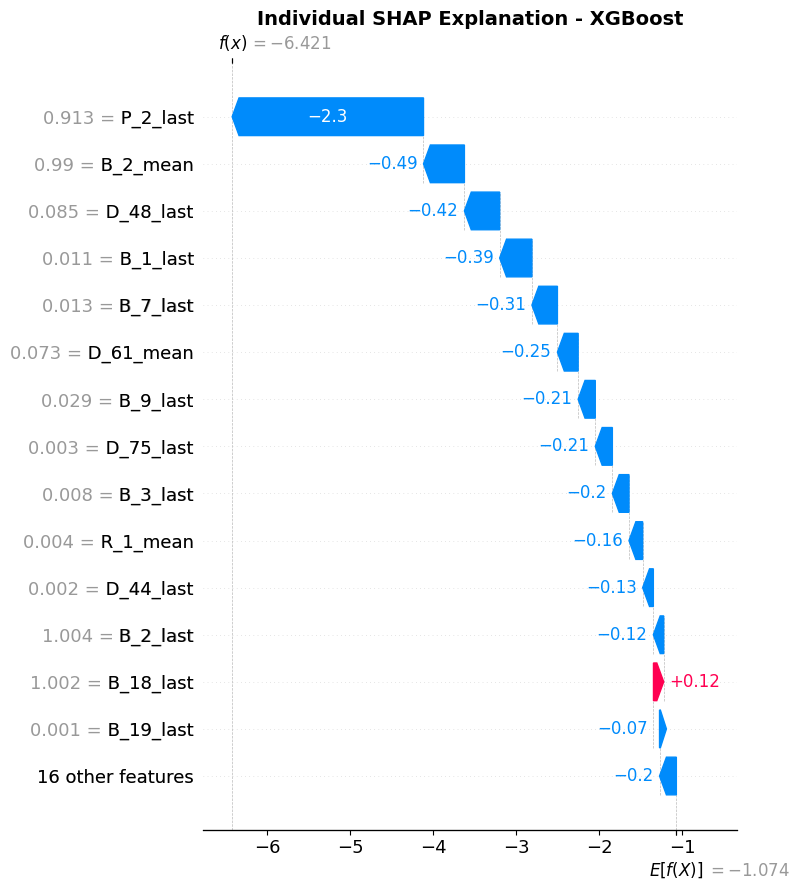

Individual SHAP waterfall plot saved successfully!


In [38]:

# ============================================================
# STEP 6.7: INDIVIDUAL CUSTOMER SHAP WATERFALL PLOT
# ============================================================

# Create the folder for SHAP visualisations if necessary.
SHAP_PATH = os.path.join(FIGURES_PATH, "shap")
os.makedirs(SHAP_PATH, exist_ok=True)

# Create a SHAP waterfall plot for the selected customer.
# Red bars push the model output towards default.
# Blue bars push the model output away from default.
# The plot displays the 15 most influential contributions.
shap.plots.waterfall(
    customer_shap_values[0],
    max_display=15,
    show=False
)

# Add a descriptive title.
plt.title(
    "Individual SHAP Explanation - XGBoost",
    fontsize=14,
    fontweight="bold"
)

# Adjust the layout.
plt.tight_layout()

# Save the plot as a high-resolution image.
plt.savefig(
    os.path.join(
        SHAP_PATH,
        "individual_customer_waterfall.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

# Display the waterfall plot.
plt.show()

print("Individual SHAP waterfall plot saved successfully!")


In [39]:

# ============================================================
# SAVE INDIVIDUAL SHAP RESULTS FOR FUTURE USE
# ============================================================

# Create folders for saved explanations.
SHAP_PATH = os.path.join(FIGURES_PATH, "shap")
SHAP_RESULTS_PATH = os.path.join(TABLES_PATH, "shap")

os.makedirs(SHAP_PATH, exist_ok=True)
os.makedirs(SHAP_RESULTS_PATH, exist_ok=True)

# Save all individual SHAP feature contributions.
customer_shap_df.to_csv(
    os.path.join(
        SHAP_RESULTS_PATH,
        "individual_customer_SHAP_explanation.csv"
    ),
    index=False
)

# Save the selected customer's prediction details.
customer_prediction = pd.DataFrame([{
    "customer_ID": customer_id,
    "actual_target": actual_target,
    "predicted_class": predicted_class,
    "default_probability": default_probability,
    "non_default_probability": non_default_probability
}])

customer_prediction.to_csv(
    os.path.join(
        SHAP_RESULTS_PATH,
        "individual_customer_prediction.csv"
    ),
    index=False
)

# Save the SHAP waterfall plot.
# The plot should already exist from Step 6.7.
waterfall_path = os.path.join(
    SHAP_PATH,
    "individual_customer_waterfall.png"
)

print("Individual customer results saved!")
print("SHAP explanation:", SHAP_RESULTS_PATH)
print("Waterfall plot:", waterfall_path)


Individual customer results saved!
SHAP explanation: /content/drive/MyDrive/AMEX_Credit_Risk_Capstone_Project/results/tables/shap
Waterfall plot: /content/drive/MyDrive/AMEX_Credit_Risk_Capstone_Project/results/figures/shap/individual_customer_waterfall.png
